# Heart Disease Classification

**Goal:** predict whether a patient has heart disease from 13 clinical measurements, and evaluate the model honestly.

**Key insight of this project:** the raw dataset contains **~70% duplicate rows**. A naive train/test split puts the same patient in both sets, which inflates accuracy (a KNN reaches ~90%). After removing duplicates and using proper validation, the realistic performance is lower. Section 3 demonstrates this explicitly.

*Final results are in the "Conclusions" section at the end.*

## 1. Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
SEED = 42

raw = pd.read_csv("data/heart_updated.csv")
print(raw.shape)
raw.head()

(1026, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


**Columns:** `age`; `sex` (1 = male); `cp` chest pain type (0-3); `trestbps` resting blood pressure; `chol` cholesterol; `fbs` fasting blood sugar > 120 (1 = yes); `restecg` resting ECG result (0-2); `thalach` max heart rate achieved; `exang` exercise-induced angina; `oldpeak` ST depression; `slope` ST slope; `ca` number of major vessels (0-4); `thal` thalassemia result; `target` (0/1) is the label to predict.

## 2. Data quality

In [2]:
print("Missing values:", int(raw.isna().sum().sum()))
n_dup = raw.duplicated().sum()
print(f"Duplicate rows: {n_dup} of {len(raw)} ({n_dup/len(raw):.1%})  ->  unique patients: {len(raw) - n_dup}")
print("\nTarget balance (raw):\n", raw["target"].value_counts())

# Suspicious category codes (kept, but worth noting)
print("\nca == 4 rows:", (raw.drop_duplicates()["ca"] == 4).sum(), "| thal == 0 rows:", (raw.drop_duplicates()["thal"] == 0).sum())

df = raw.drop_duplicates().reset_index(drop=True)
print("\nClean dataset:", df.shape)
print(df["target"].value_counts(normalize=True).round(3).to_dict())

Missing values: 0
Duplicate rows: 723 of 1026 (70.5%)  ->  unique patients: 303

Target balance (raw):
 target
1    527
0    499
Name: count, dtype: int64

ca == 4 rows: 4 | thal == 0 rows: 2

Clean dataset: (303, 14)
{1: 0.545, 0: 0.455}


## 3. Why duplicates matter: the data-leakage demo

The common workflow (random split, then KNN) gives a high score on the raw data. I repeat it on the raw and the deduplicated data, using the **same unscaled KNN**, to show how much of the score comes from duplicates.

In [3]:
def knn_split_accuracy(data, k):
    X, y = data.drop(columns="target"), data["target"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    acc = KNeighborsClassifier(n_neighbors=k).fit(Xtr, ytr).score(Xte, yte)
    # how many test rows have an exact copy in the training set?
    train_keys = set(map(tuple, Xtr.values))
    leaked = np.mean([tuple(r) in train_keys for r in Xte.values])
    return acc, leaked

rows = []
for name, data in [("Raw (with duplicates)", raw), ("Deduplicated", df)]:
    for k in (3, 5):
        acc, leaked = knn_split_accuracy(data, k)
        rows.append({"data": name, "k": k, "test_accuracy": round(acc, 3), "test_rows_with_exact_copy_in_train": f"{leaked:.0%}"})
pd.DataFrame(rows)

,data,k,test_accuracy,test_rows_with_exact_copy_in_train
0,Raw (with duplicates),3,0.903,97%
1,Raw (with duplicates),5,0.748,97%
2,Deduplicated,3,0.623,0%
3,Deduplicated,5,0.623,0%


On the raw data a large share of the test rows have an identical twin in the training set, so the model is mostly *remembering*, not generalising. This also explains the odd jump between K=3 and K=5 on the raw data: K=3 memorises copies better. On clean data the score drops sharply. All results below use the deduplicated data.

## 4. Exploratory analysis

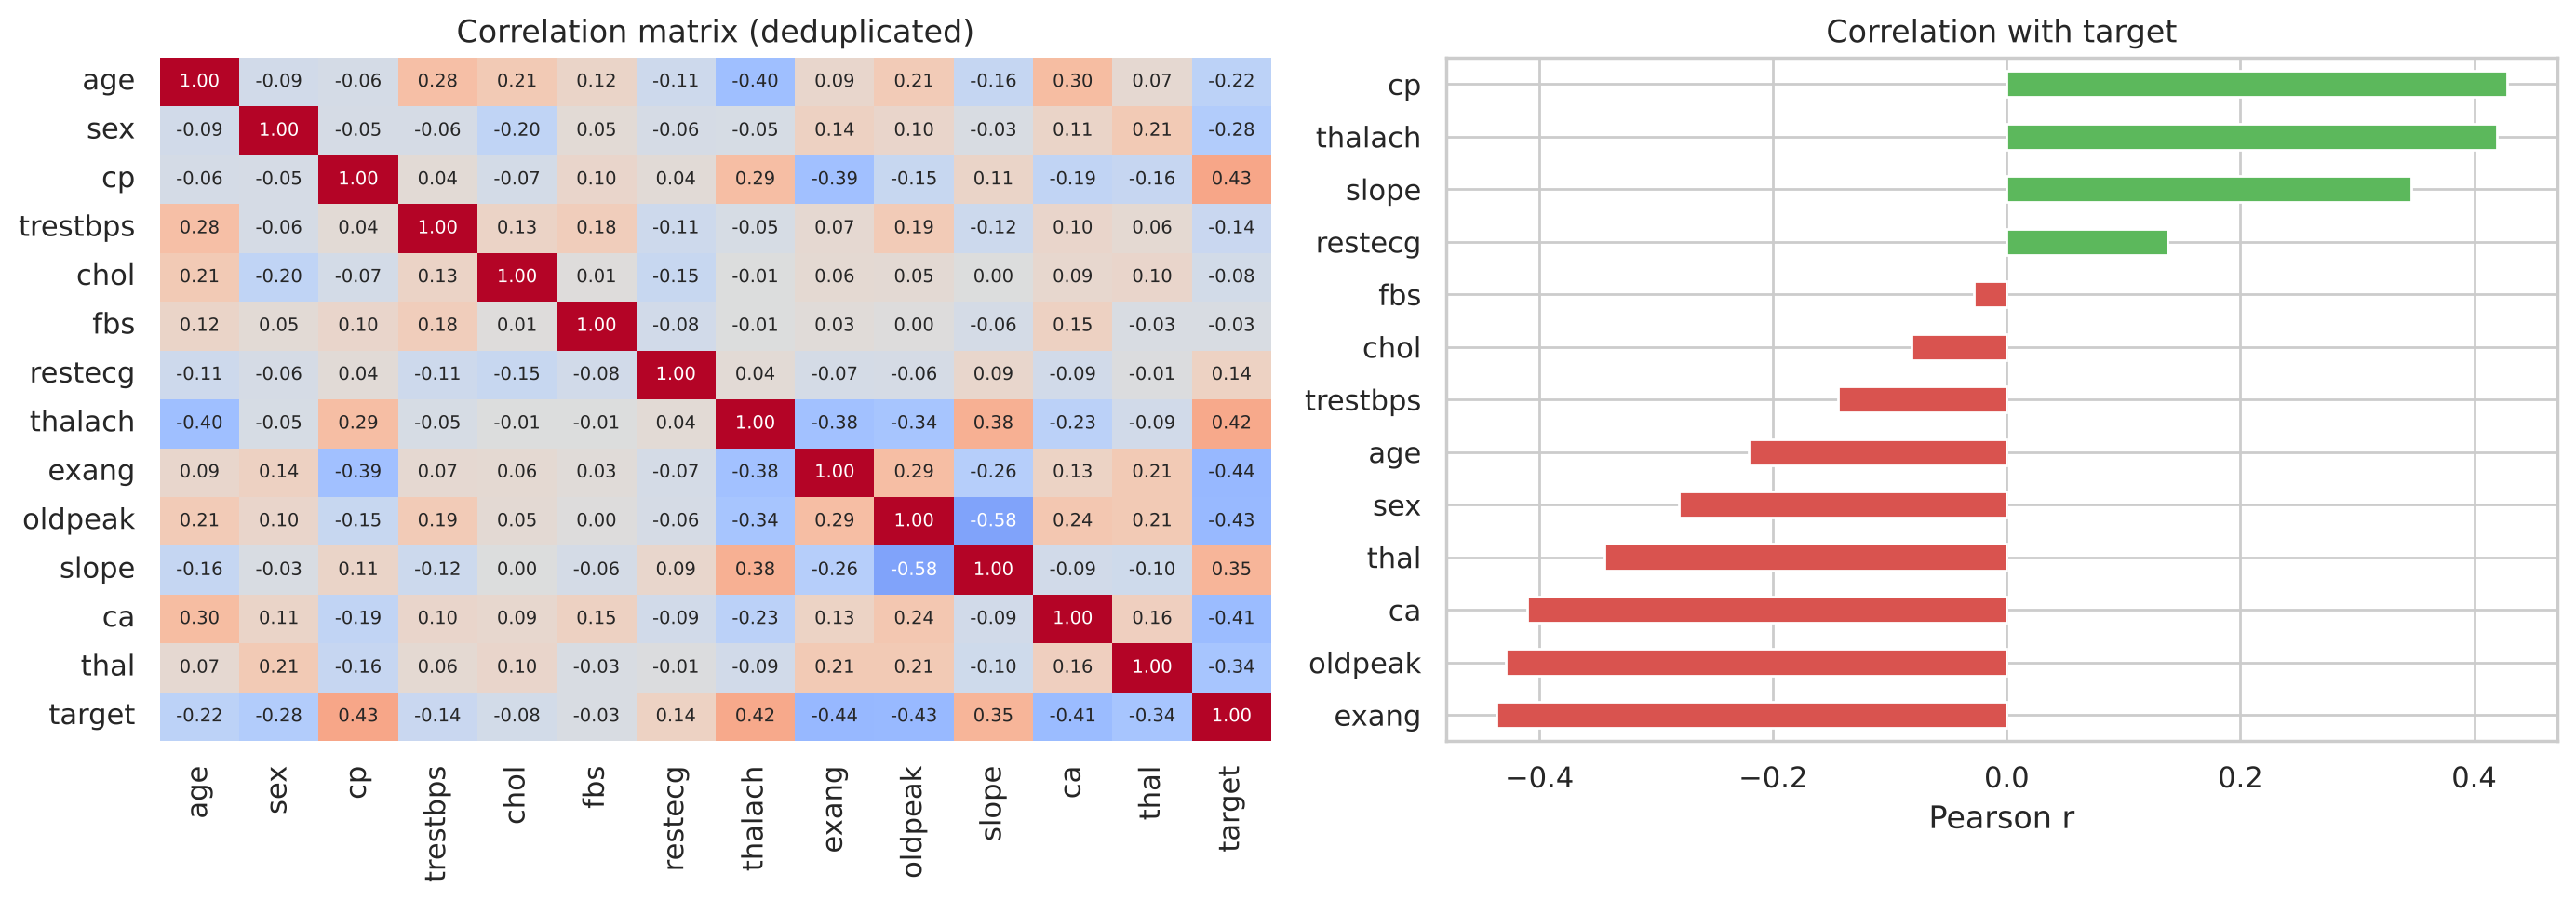

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], annot_kws={"size": 7}, cbar=False)
axes[0].set_title("Correlation matrix (deduplicated)")
corr_t = df.corr()["target"].drop("target").sort_values()
corr_t.plot.barh(ax=axes[1], color=["#d9534f" if v < 0 else "#5cb85c" for v in corr_t])
axes[1].set_title("Correlation with target"); axes[1].set_xlabel("Pearson r")
plt.tight_layout(); plt.show()

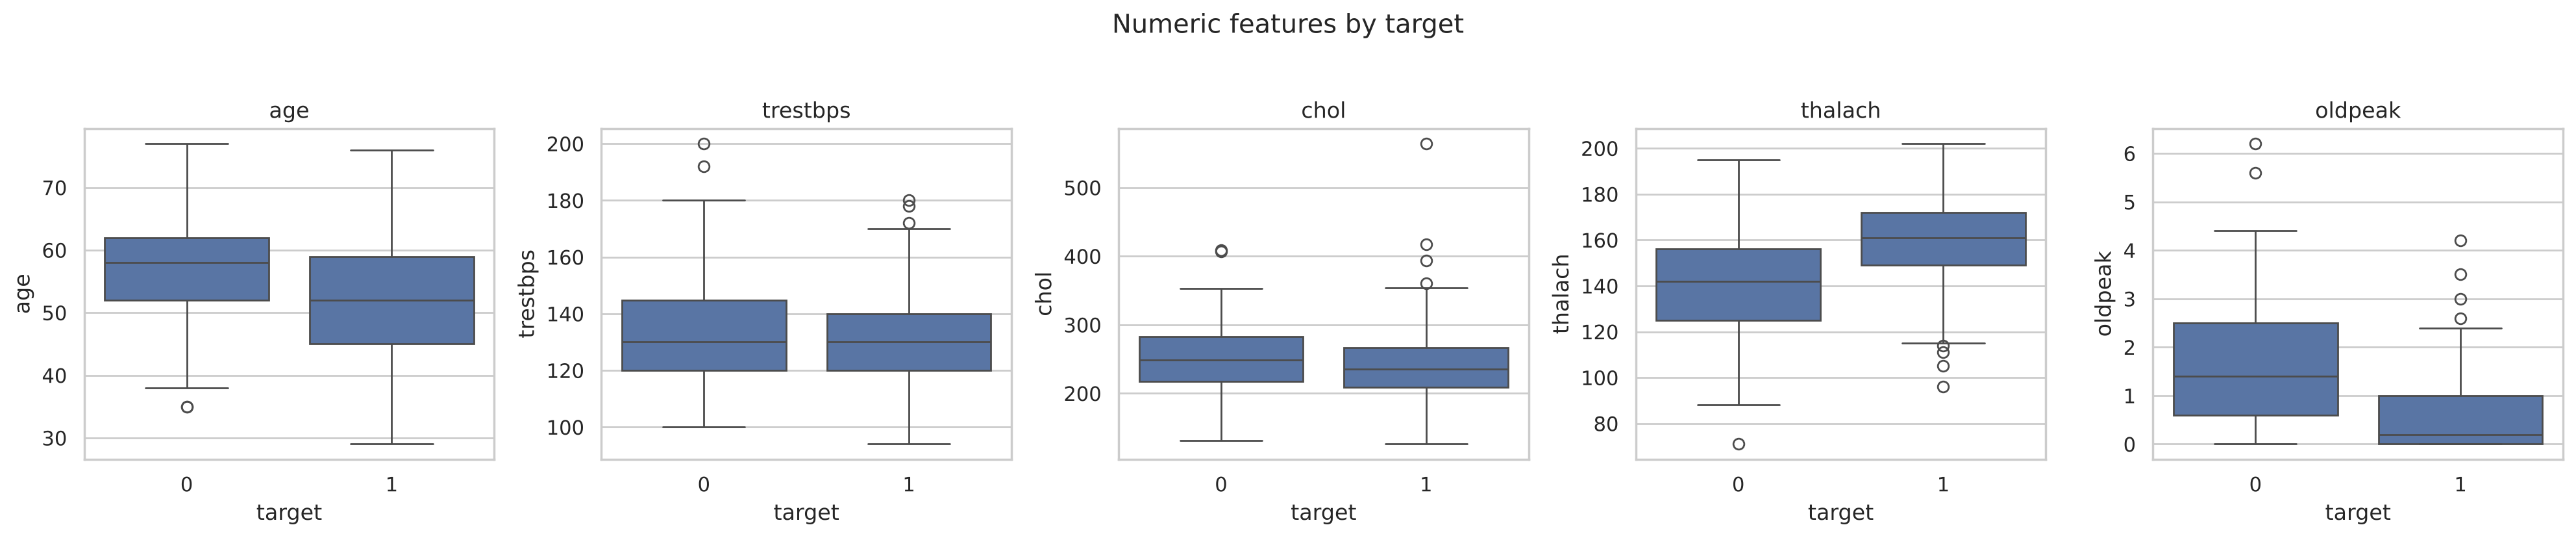

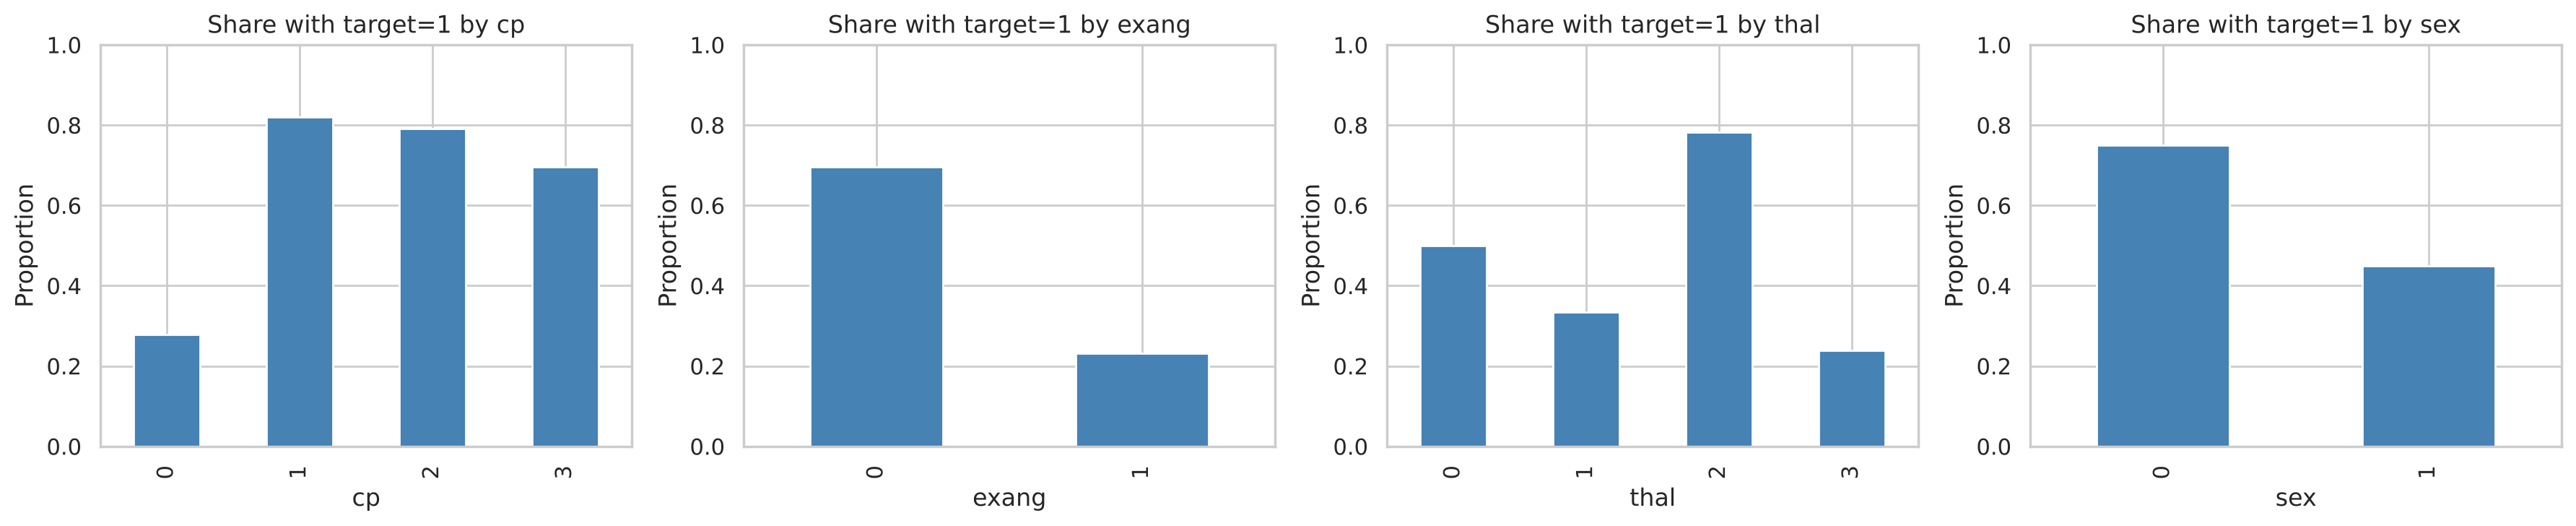

In [5]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x="target", y=c, ax=ax)
    ax.set_title(c); ax.set_xlabel("target")
plt.suptitle("Numeric features by target", y=1.03); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, ["cp", "exang", "thal", "sex"]):
    df.groupby(c)["target"].mean().plot.bar(ax=ax, color="steelblue")
    ax.set_title(f"Share with target=1 by {c}"); ax.set_ylabel("Proportion"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 5. Modelling

- **Stratified** 80/20 split (keeps class balance); the test set is touched only once, at the end.
- A `Pipeline` so that scaling/encoding is fitted **only on training folds** (no preprocessing leakage). KNN needs scaled features.
- Models: KNN (K chosen by cross-validation), Logistic Regression, Random Forest.
- Metrics: accuracy, **recall** (missing a sick patient is the costly error), F1 and ROC AUC, averaged over repeated 5-fold CV.

Train: (242, 13) | Test: (61, 13)


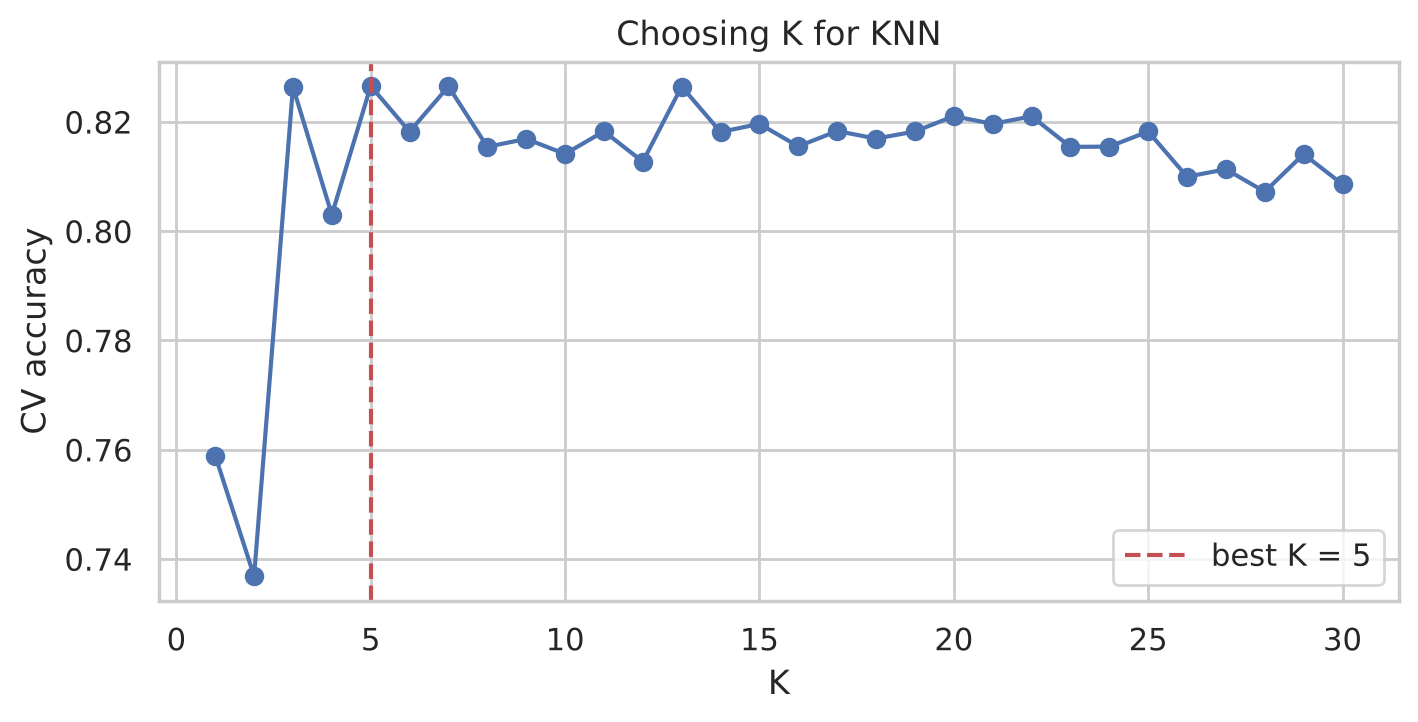

In [6]:
X, y = df.drop(columns="target"), df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

num = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat = ["cp", "restecg", "slope", "thal"]
passthrough_cols = ["sex", "fbs", "exang", "ca"]   # binary flags and the vessel count, used as-is

def preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("pass", "passthrough", passthrough_cols),
    ])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

# choose K for KNN by cross-validation
ks = range(1, 31)
knn_scores = [cross_val_score(Pipeline([("pre", preprocessor()), ("m", KNeighborsClassifier(k))]), X_train, y_train, cv=cv).mean() for k in ks]
best_k = list(ks)[int(np.argmax(knn_scores))]
plt.figure(figsize=(8, 3.5)); plt.plot(list(ks), knn_scores, marker="o")
plt.axvline(best_k, color="r", ls="--", label=f"best K = {best_k}")
plt.xlabel("K"); plt.ylabel("CV accuracy"); plt.title("Choosing K for KNN"); plt.legend(); plt.show()

In [7]:
models = {
    f"KNN (K={best_k})": KNeighborsClassifier(n_neighbors=best_k),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED),
}
scoring = ["accuracy", "recall", "f1", "roc_auc"]
rows = []
for name, m in models.items():
    res = cross_validate(Pipeline([("pre", preprocessor()), ("m", m)]), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name, **{s: res[f"test_{s}"].mean() for s in scoring}, "accuracy_std": res["test_accuracy"].std()})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,accuracy,recall,f1,roc_auc,accuracy_std
model,,,,,
KNN (K=5),0.827,0.877,0.847,0.886,0.051
Logistic Regression,0.835,0.877,0.853,0.902,0.056
Random Forest,0.846,0.902,0.865,0.916,0.050


## 6. Final evaluation on the held-out test set

Selected model (best CV ROC AUC): Random Forest
Test accuracy: 0.787 | ROC AUC: 0.876

                precision    recall  f1-score   support

no disease (0)       0.78      0.75      0.76        28
   disease (1)       0.79      0.82      0.81        33

      accuracy                           0.79        61
     macro avg       0.79      0.78      0.78        61
  weighted avg       0.79      0.79      0.79        61



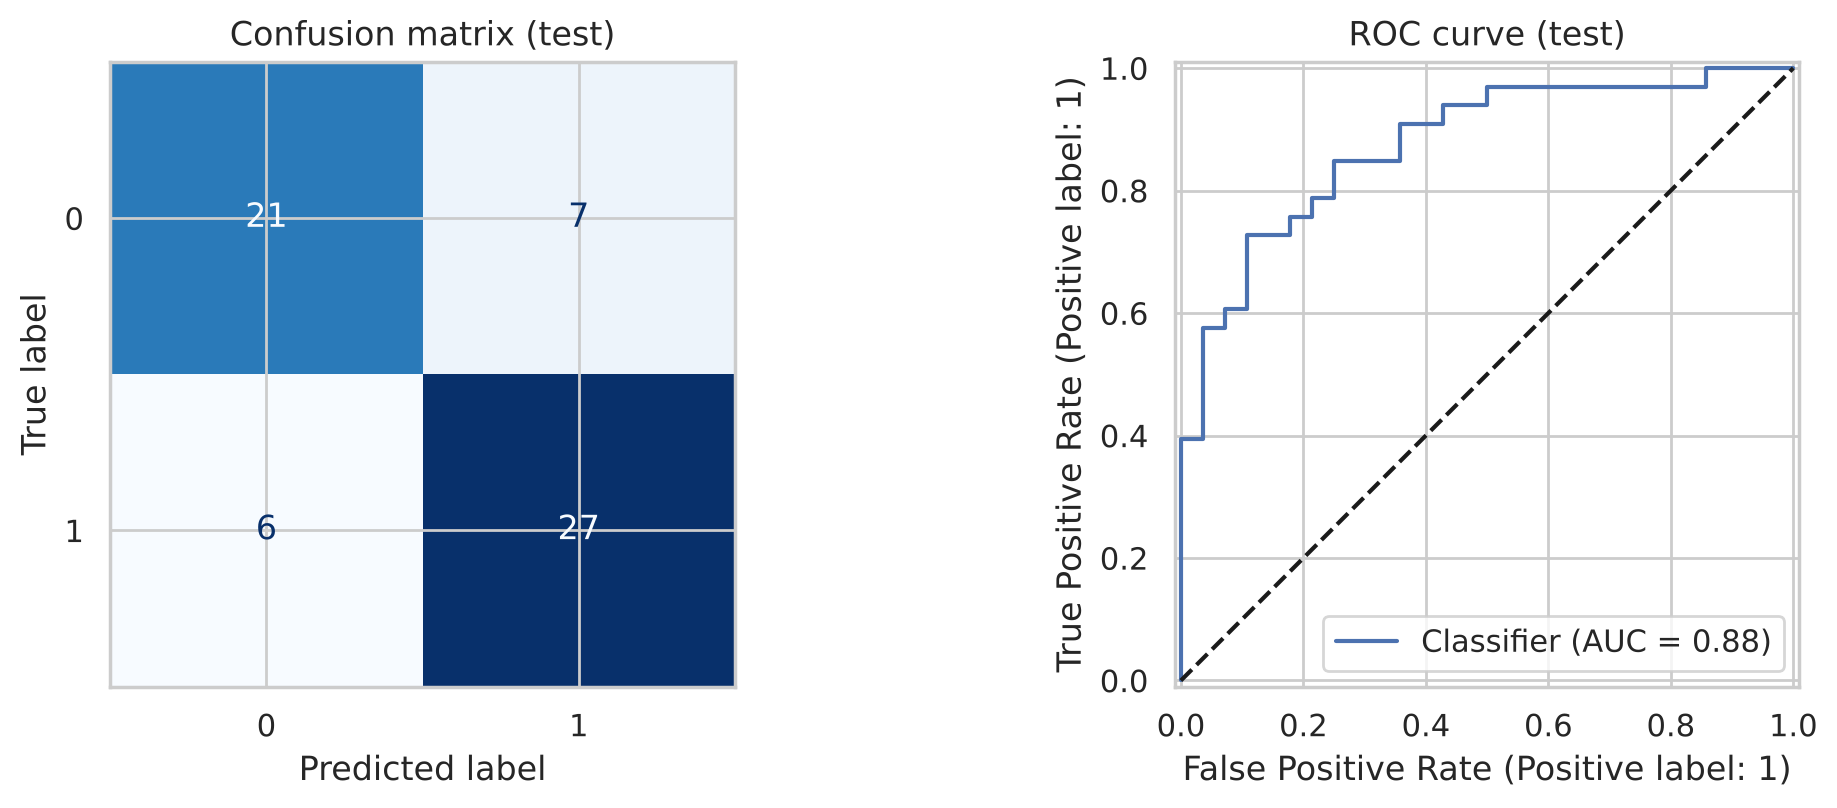

Note: the test set has only 61 patients, so this estimate is noisy; the cross-validated numbers above are more reliable.


In [8]:
best_name = cv_table["roc_auc"].idxmax()
final = Pipeline([("pre", preprocessor()), ("m", models[best_name])]).fit(X_train, y_train)
pred = final.predict(X_test); proba = final.predict_proba(X_test)[:, 1]
print("Selected model (best CV ROC AUC):", best_name)
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f} | ROC AUC: {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, pred, target_names=["no disease (0)", "disease (1)"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1]); axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curve (test)")
plt.tight_layout(); plt.show()
print(f"Note: the test set has only {len(y_test)} patients, so this estimate is noisy; the cross-validated numbers above are more reliable.")

### Robustness: does the model ranking depend on the split?
With only 303 patients a single split is noisy, so I repeat the stratified split 10 times and compare test ROC AUC for the three models.

In [9]:
rob = {k: [] for k in models}
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=100 + s)
    for name, m in models.items():
        p_ = Pipeline([("pre", preprocessor()), ("m", clone(m))]).fit(Xa, ya).predict_proba(Xb)[:, 1]
        rob[name].append(roc_auc_score(yb, p_))
rob_table = pd.DataFrame({k: {"mean AUC": np.mean(v), "std": np.std(v), "min": np.min(v), "max": np.max(v)} for k, v in rob.items()}).T.round(3)
rob_table

,mean AUC,std,min,max
KNN (K=5),0.876,0.035,0.805,0.916
Logistic Regression,0.906,0.025,0.842,0.931
Random Forest,0.915,0.022,0.864,0.951


### Which features matter?

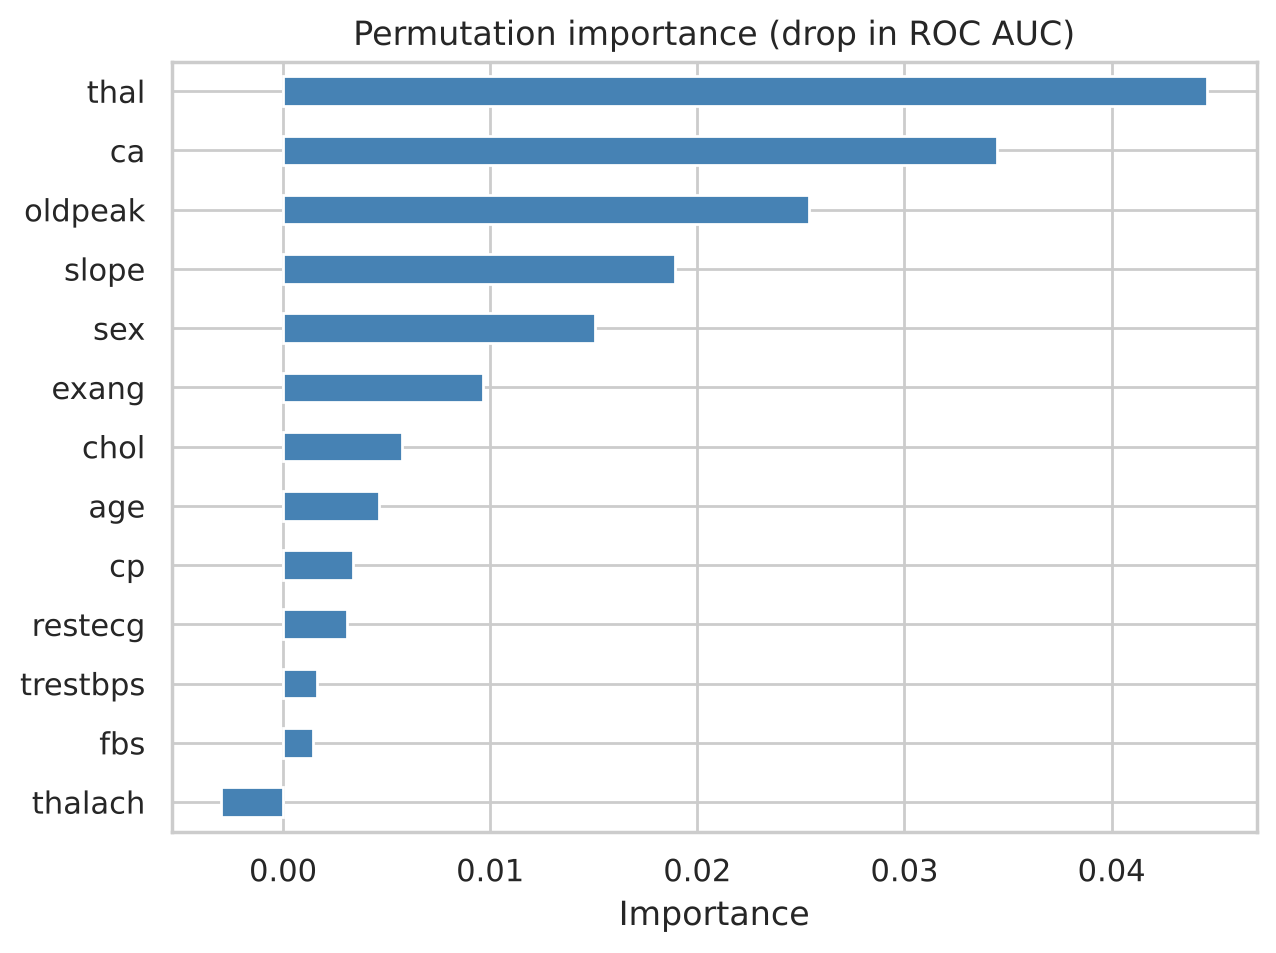

In [10]:
imp = permutation_importance(final, X_test, y_test, n_repeats=30, random_state=SEED, scoring="roc_auc")
imp_s = pd.Series(imp.importances_mean, index=X.columns).sort_values()
imp_s.plot.barh(figsize=(7, 5), color="steelblue")
plt.title("Permutation importance (drop in ROC AUC)"); plt.xlabel("Importance"); plt.show()

### Predicting a new patient
In the original notebook the "new patient" cell scaled the patient but then predicted on the first rows of `X_test` instead, so the patient was never actually classified. Here the pipeline takes the patient directly and returns a probability.

In [11]:
patient = pd.DataFrame([[52, 1, 1, 129, 241, 0, 1, 159, 0, 0.6, 2, 0, 2]], columns=X.columns)
p = final.predict_proba(patient)[0, 1]
print(f"Predicted class: {int(p >= 0.5)}  |  probability of target=1: {p:.2f}")

Predicted class: 1  |  probability of target=1: 0.93


## 7. Conclusions

In [12]:
r = cv_table.loc[best_name]
gap = abs(np.mean(rob["Logistic Regression"]) - np.mean(rob["Random Forest"]))
print(f'''1. Data quality: {n_dup} of {len(raw)} rows ({n_dup/len(raw):.0%}) were exact duplicates; only {len(df)} unique patients remain.
2. The ~90% accuracy of the naive split is mostly leakage (identical rows in train and test). On clean data the same unscaled KNN is far worse.
3. With scaling, proper CV and deduplicated data, the models reach about {cv_table.accuracy.min():.0%}-{cv_table.accuracy.max():.0%} CV accuracy.
4. Selected model: {best_name} (CV accuracy {r.accuracy:.2f}, recall {r.recall:.2f}, ROC AUC {r.roc_auc:.2f}); test accuracy {accuracy_score(y_test, pred):.2f}.
5. Most influential features: {", ".join(imp_s.index[::-1][:3])}.
6. Over 10 random splits, Logistic Regression and Random Forest differ by only {gap:.3f} test AUC on average: treat them as equivalent, do not over-interpret the ranking.

Limitations: only {len(df)} patients, so estimates are noisy and the test set is small; no external validation.
This is a learning project, not a medical tool.''')

1. Data quality: 723 of 1026 rows (70%) were exact duplicates; only 303 unique patients remain.
2. The ~90% accuracy of the naive split is mostly leakage (identical rows in train and test). On clean data the same unscaled KNN is far worse.
3. With scaling, proper CV and deduplicated data, the models reach about 83%-85% CV accuracy.
4. Selected model: Random Forest (CV accuracy 0.85, recall 0.90, ROC AUC 0.92); test accuracy 0.79.
5. Most influential features: thal, ca, oldpeak.
6. Over 10 random splits, Logistic Regression and Random Forest differ by only 0.009 test AUC on average: treat them as equivalent, do not over-interpret the ranking.

Limitations: only 303 patients, so estimates are noisy and the test set is small; no external validation.
This is a learning project, not a medical tool.
